In [1]:
from MultiAgent_DQ import *
import numpy as np
from utils import *
import pandas as pd  
from tqdm import tqdm  
import itertools


## Single Run

In [28]:
M_value = 100

In [29]:
algo = Algorithm(e=0.1, lambda_val=0, 
                 alpha=0.05, delta=0.8,
                 random_uniform=True, tolerance=1e-7, 
                 M=M_value, verbose=False)
q1_history_per_sample, q2_history_per_sample = algo.run()
dfs_1  = convert_dict_to_mean_df(q1_history_per_sample, mean= False)
dfs_2  = convert_dict_to_mean_df(q2_history_per_sample, mean= False)
strategy_played_1 = {}
strategy_played_2 = {}

# Iterate over the dataframe rows
for i in range(len(dfs_1)):
    last_1 = dfs_1[i].iloc[-1]  # Get the last row using iloc (optimized)
    last_2 = dfs_2[i].iloc[-1]  # Same for second dataframe

    # Define conditions for both players
    GT_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
    AD_1 = (last_1['Q1'] < last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
    AC_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] > last_1['Q4'])

    GT_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
    AD_2 = (last_2['Q1'] < last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
    AC_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] > last_2['Q4'])

    # Assign strategy for both players
    strategy_map = {
        AD_1: 1,  # Always Defecting
        GT_1: 2,  # Grim Trigger
        AC_1: 3,  # Always Cooperating
    }

    # Handle strategy for player 1 and player 2
    for player, strategy in [(AD_1, strategy_map), (GT_1, strategy_map), (AC_1, strategy_map)]:
        if player:
            strategy_played_1[i] = strategy[player]
            break  # Once a strategy is found, break the loop to avoid multiple assignments

    for player, strategy in [(AD_2, strategy_map), (GT_2, strategy_map), (AC_2, strategy_map)]:
        if player:
            strategy_played_2[i] = strategy[player]
            break  # Once a strategy is found, break the loop to avoid multiple assignments

# Convert strategy_played_1 and strategy_played_2 dictionaries to DataFrames
df_strategy_1 = pd.DataFrame(list(strategy_played_1.items()), columns=['Index', 'Strategy_1'])
df_strategy_2 = pd.DataFrame(list(strategy_played_2.items()), columns=['Index', 'Strategy_2'])

# Merge the two DataFrames on 'Index'
df_merged = pd.merge(df_strategy_1, df_strategy_2, on='Index')

# Optionally, set 'Index' as the DataFrame index (if you need it)
df_merged.set_index('Index', inplace=True)
# Count how many times Strategy_1 and Strategy_2 are different
count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()

# Display the result
print(f"Number of times Strategy_1 and Strategy_2 are different: {count_diff}")
# Count how many times both Strategy_1 and Strategy_2 have the value 1
P_AD = ((df_merged['Strategy_1'] == 1) & (df_merged['Strategy_2'] == 1)).sum()/M_value

# Count how many times both Strategy_1 and Strategy_2 have the value 2
P_GT = ((df_merged['Strategy_1'] == 2) & (df_merged['Strategy_2'] == 2)).sum()/M_value

# Display the results
print(f"P_AD: {P_AD}")
print(f"P_GT: {P_GT}")
# Count how many times Strategy_1 and Strategy_2 are different
count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()/M_value

# Display the result
print(f"Number of times Strategy_1 and Strategy_2 are different (NO CONVERGENCE): {count_diff}")


KeyboardInterrupt: 

## Simulation

In [14]:
# For tracking progress
M_value = 100
alpha_values = [0.05,0.1,0.2]
lambda_values = [0.05,0.1,0.2]
delta_values = [0.5,0.6,0.7]  # 1000 equally spaced values from 0 to 0.999
epsilon_values = [0.05,0.1,0.2]  # 1000 equally spaced values from 0 to 0.99
random_uniform_values = [False]

# Store results
results = []

# Generate all parameter combinations
parameter_combinations = list(itertools.product(alpha_values, lambda_values, epsilon_values, delta_values, random_uniform_values))

# Iterate through each parameter combination with tqdm progress bar
for alpha, lambda_val, e, delta, random_uniform in tqdm(parameter_combinations, desc="Processing combinations"):
    # Initialize the algorithm with the current parameter combination
    algo = Algorithm(e=e, lambda_val=lambda_val, 
                     alpha=alpha, delta=delta,
                     random_uniform=random_uniform, tolerance=1e-5, 
                     M=M_value, verbose=False)

    # Run the algorithm
    q1_history_per_sample, q2_history_per_sample = algo.run()

    # Convert results to dataframes
    dfs_1 = convert_dict_to_mean_df(q1_history_per_sample, mean=False)
    dfs_2 = convert_dict_to_mean_df(q2_history_per_sample, mean=False)

    # Initialize strategies played
    strategy_played_1 = {}
    strategy_played_2 = {}

    # Iterate over the dataframe rows
    for i in range(len(dfs_1)):
        last_1 = dfs_1[i].iloc[-1]  # Get the last row using iloc
        last_2 = dfs_2[i].iloc[-1]

        # Define conditions for both players
        GT_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AD_1 = (last_1['Q1'] < last_1['Q3']) & (last_1['Q2'] < last_1['Q4'])
        AC_1 = (last_1['Q1'] > last_1['Q3']) & (last_1['Q2'] > last_1['Q4'])

        GT_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AD_2 = (last_2['Q1'] < last_2['Q3']) & (last_2['Q2'] < last_2['Q4'])
        AC_2 = (last_2['Q1'] > last_2['Q3']) & (last_2['Q2'] > last_2['Q4'])

        # Assign strategy for both players
        strategy_map = {
            AD_1: 1,  # Always Defecting
            GT_1: 2,  # Grim Trigger
            AC_1: 3,  # Always Cooperating
        }

        for player, strategy in [(AD_1, strategy_map), (GT_1, strategy_map), (AC_1, strategy_map)]:
            if player:
                strategy_played_1[i] = strategy[player]
                break

        for player, strategy in [(AD_2, strategy_map), (GT_2, strategy_map), (AC_2, strategy_map)]:
            if player:
                strategy_played_2[i] = strategy[player]
                break

    # Convert strategy_played_1 and strategy_played_2 dictionaries to DataFrames
    df_strategy_1 = pd.DataFrame(list(strategy_played_1.items()), columns=['Index', 'Strategy_1'])
    df_strategy_2 = pd.DataFrame(list(strategy_played_2.items()), columns=['Index', 'Strategy_2'])

    # Merge the two DataFrames on 'Index'
    df_merged = pd.merge(df_strategy_1, df_strategy_2, on='Index')

    # Optionally, set 'Index' as the DataFrame index (if you need it)
    df_merged.set_index('Index', inplace=True)

    # Count how many times Strategy_1 and Strategy_2 are different
    count_diff = (df_merged['Strategy_1'] != df_merged['Strategy_2']).sum()

    # Count how many times both Strategy_1 and Strategy_2 have the value 1
    P_AD = ((df_merged['Strategy_1'] == 1) & (df_merged['Strategy_2'] == 1)).sum() / M_value

    # Count how many times both Strategy_1 and Strategy_2 have the value 2
    P_GT = ((df_merged['Strategy_1'] == 2) & (df_merged['Strategy_2'] == 2)).sum() / M_value

    # Store results for this parameter combination
    results.append({
        'alpha': alpha,
        'lambda': lambda_val,
        'e': e,
        'delta': delta,
        'random_uniform': random_uniform,
        'P_AD': P_AD,
        'P_GT': P_GT,
        'nonconv': count_diff
    })

# Optionally, save results to a file
results_df = pd.DataFrame(results)
results_df.to_csv("results.csv", index=False)


Processing combinations: 100%|██████████| 81/81 [02:09<00:00,  1.60s/it]


<Axes: >

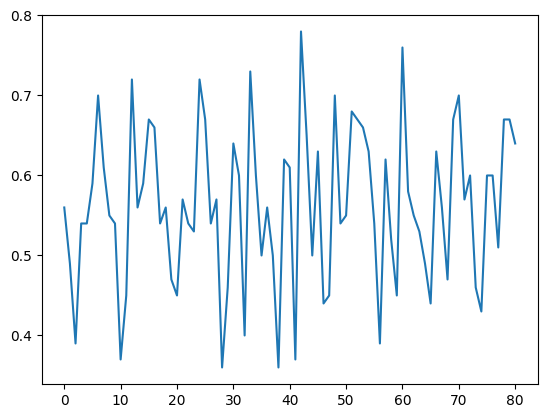

In [15]:
results_df['P_AD'].plot()

In [32]:
df = pd.read_csv("result_1_correct.csv")
df


,alpha,lambda,e,delta,random_uniform,P_AD,P_GT
0,0.05,0.05,0.05,0.010000,False,1.0,0.0
1,0.05,0.05,0.05,0.043793,False,1.0,0.0
2,0.05,0.05,0.05,0.077586,False,1.0,0.0
3,0.05,0.05,0.05,0.111379,False,1.0,0.0
4,0.05,0.05,0.05,0.145172,False,1.0,0.0
...,...,...,...,...,...,...,...
8095,0.20,0.20,0.79,0.854828,False,1.0,0.0
8096,0.20,0.20,0.79,0.888621,False,1.0,0.0
8097,0.20,0.20,0.79,0.922414,False,1.0,0.0
8098,0.20,0.20,0.79,0.956207,False,1.0,0.0


In [21]:
df['P_AD'] = df['P_AD']*100/5
df['P_GT']= df['P_GT']*100/5

In [23]:
df.to_csv('./result_1_correct.csv')

<Axes: >

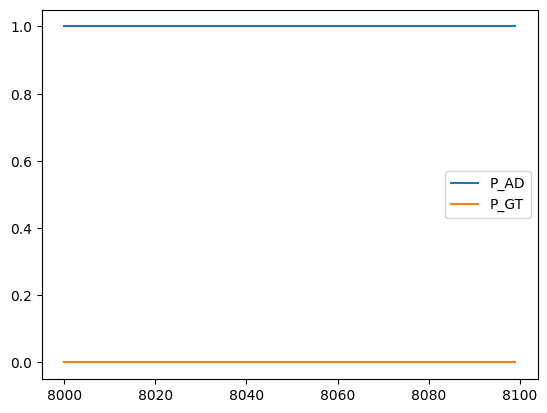

In [26]:
df[['P_AD', 'P_GT']].tail(100).plot()

In [ ]:
df

,alpha,lambda,e,delta,random_uniform,P_AD,P_GT
0,0.05,0.05,0.05,0.010000,False,1.0,0.0
1,0.05,0.05,0.05,0.043793,False,1.0,0.0
2,0.05,0.05,0.05,0.077586,False,1.0,0.0
3,0.05,0.05,0.05,0.111379,False,1.0,0.0
4,0.05,0.05,0.05,0.145172,False,1.0,0.0
...,...,...,...,...,...,...,...
8095,0.20,0.20,0.79,0.854828,False,1.0,0.0
8096,0.20,0.20,0.79,0.888621,False,1.0,0.0
8097,0.20,0.20,0.79,0.922414,False,1.0,0.0
8098,0.20,0.20,0.79,0.956207,False,1.0,0.0


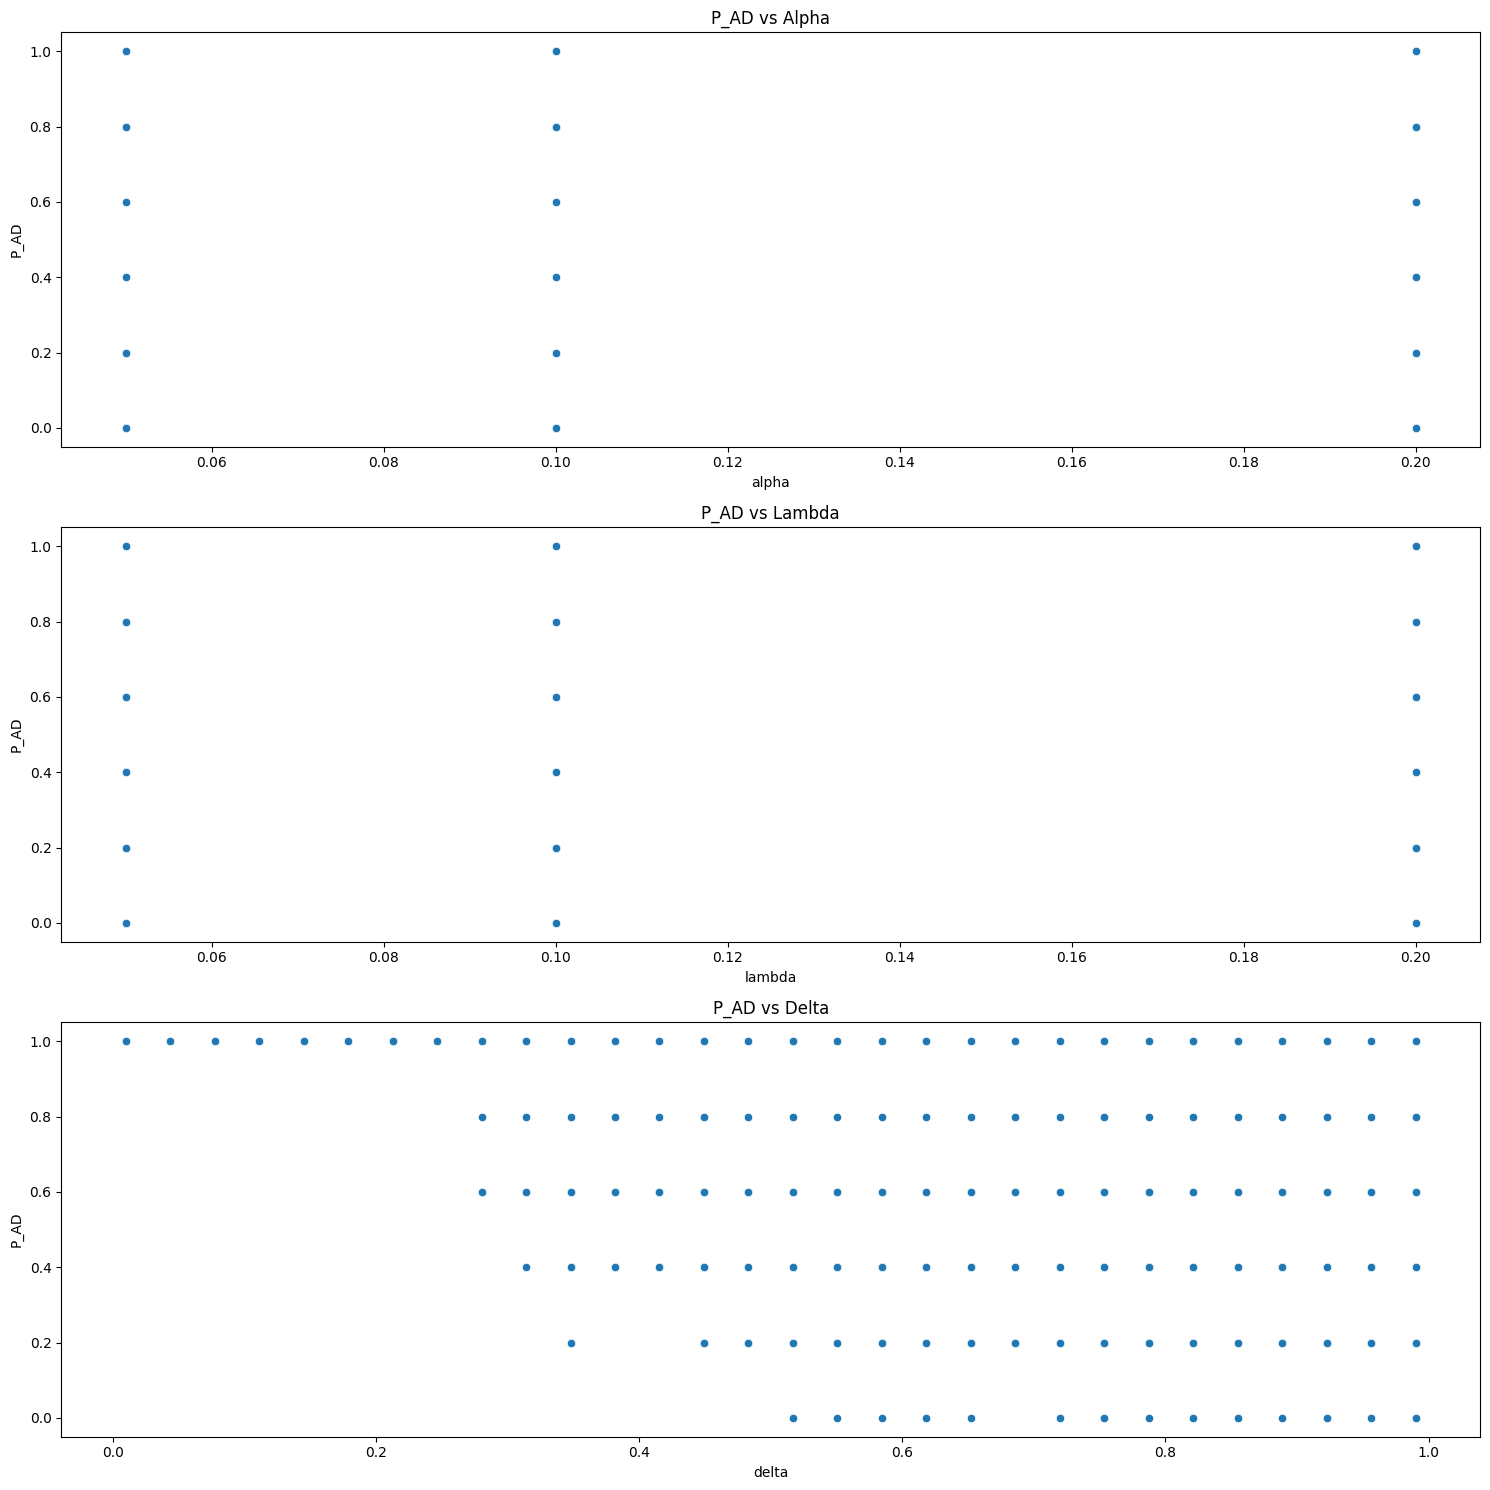

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plots to visualize relationships
fig, axes = plt.subplots(3, 1, figsize=(15, 15))

# Scatter plot for alpha vs P_AD
sns.scatterplot(x='alpha', y='P_AD', data=df, ax=axes[0])
axes[0].set_title('P_AD vs Alpha')

# Scatter plot for lambda vs P_AD
sns.scatterplot(x='lambda', y='P_AD', data=df, ax=axes[1])
axes[1].set_title('P_AD vs Lambda')

# Scatter plot for delta vs P_AD
sns.scatterplot(x='delta', y='P_AD', data=df, ax=axes[2])
axes[2].set_title('P_AD vs Delta')

plt.tight_layout()
plt.show()


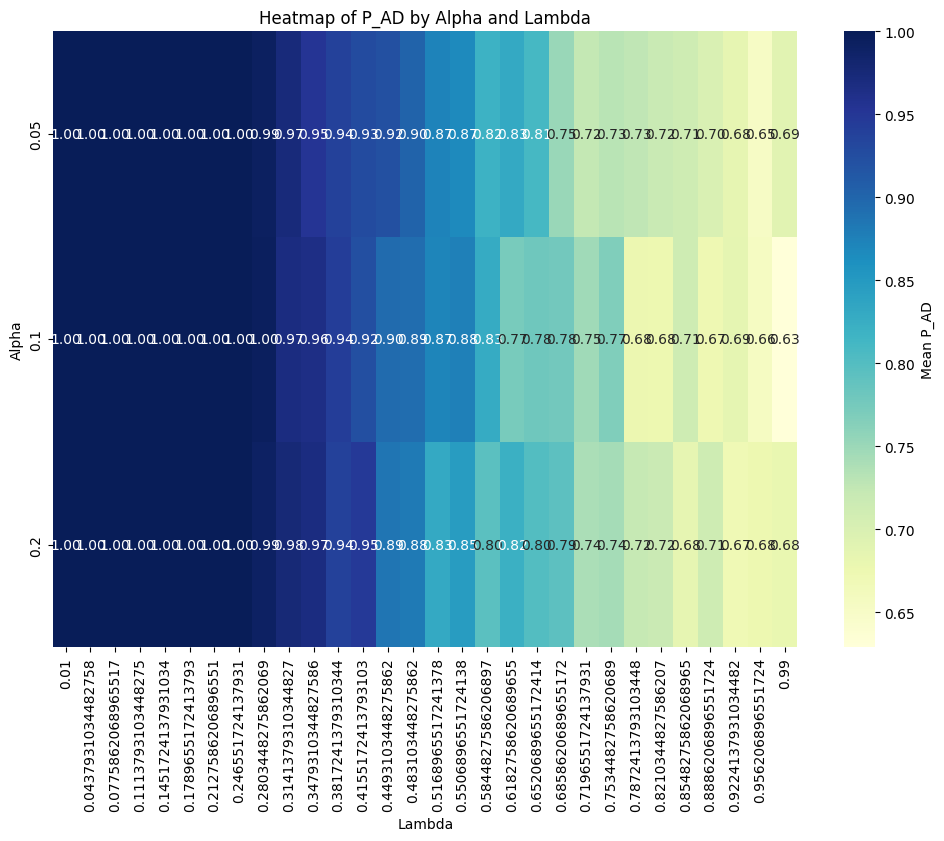

In [41]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming df is your dataframe

# Pivot the dataframe to create a matrix where 'alpha' and 'lambda' are the indices and columns
heatmap_data = df.pivot_table(index='alpha', columns='delta', values='P_AD', aggfunc='mean')

# Plot the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=True, fmt='.2f', cbar_kws={'label': 'Mean P_AD'})

# Set titles and labels
plt.title('Heatmap of P_AD by Alpha and Lambda')
plt.xlabel('Lambda')
plt.ylabel('Alpha')

plt.show()
